In [1]:
import numpyro
numpyro.set_host_device_count(4)
import jax

jax.config.update("jax_num_cpu_devices", 4)
jax.local_device_count()

/home/athapar/code/msinf/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


4

In [3]:
import numpy as np

data = np.load("/home/athapar/code/msinf/outputs/2026-10-14/15-54-43/numpyro_jamie_samples.npz")

data["IB0"].shape


(4, 400)

/home/athapar/code/msinf/.venv/lib/python3.12/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


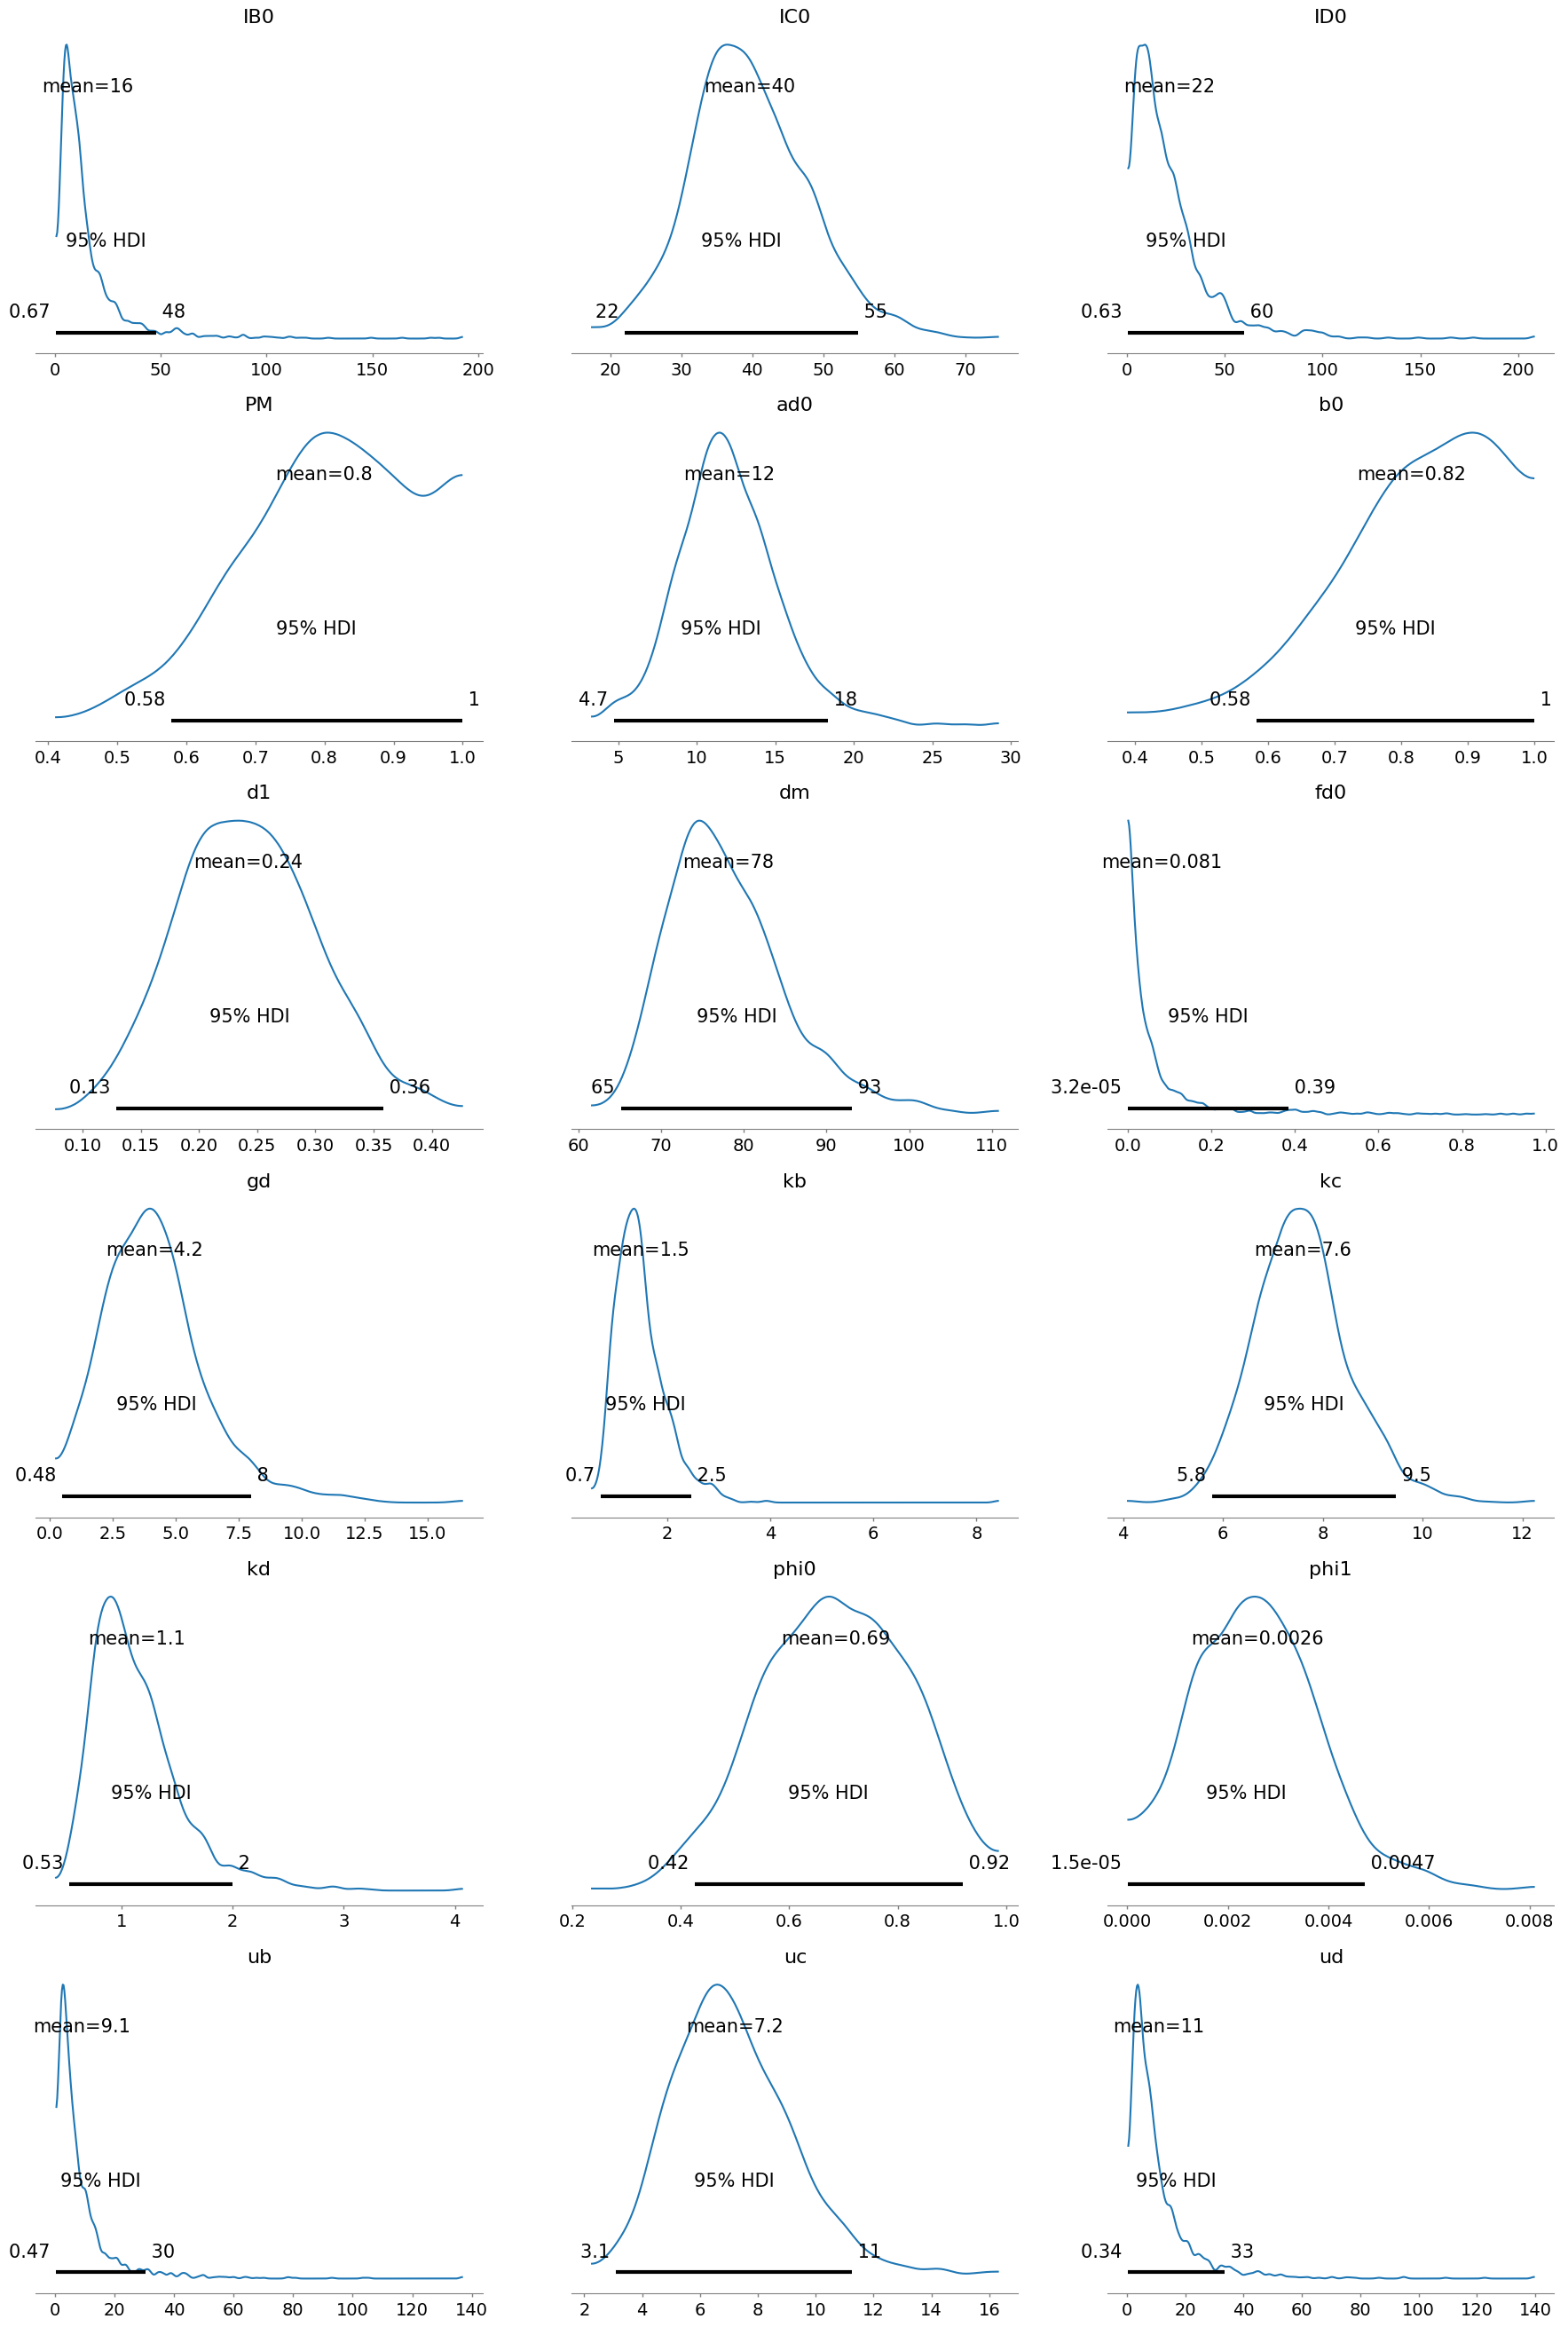

In [4]:
import arviz as az
import matplotlib.pyplot as plt
from msinf.priors import CORE_PARAMS

posterior = {
    name: data[name]
    for name in data.files
    if not name.startswith(("warmup__", "__"))
}
idata = az.from_dict(posterior=posterior)

params = [name for name in CORE_PARAMS if name in posterior]

az.plot_posterior(idata, var_names=params, hdi_prob=0.95)
plt.show()

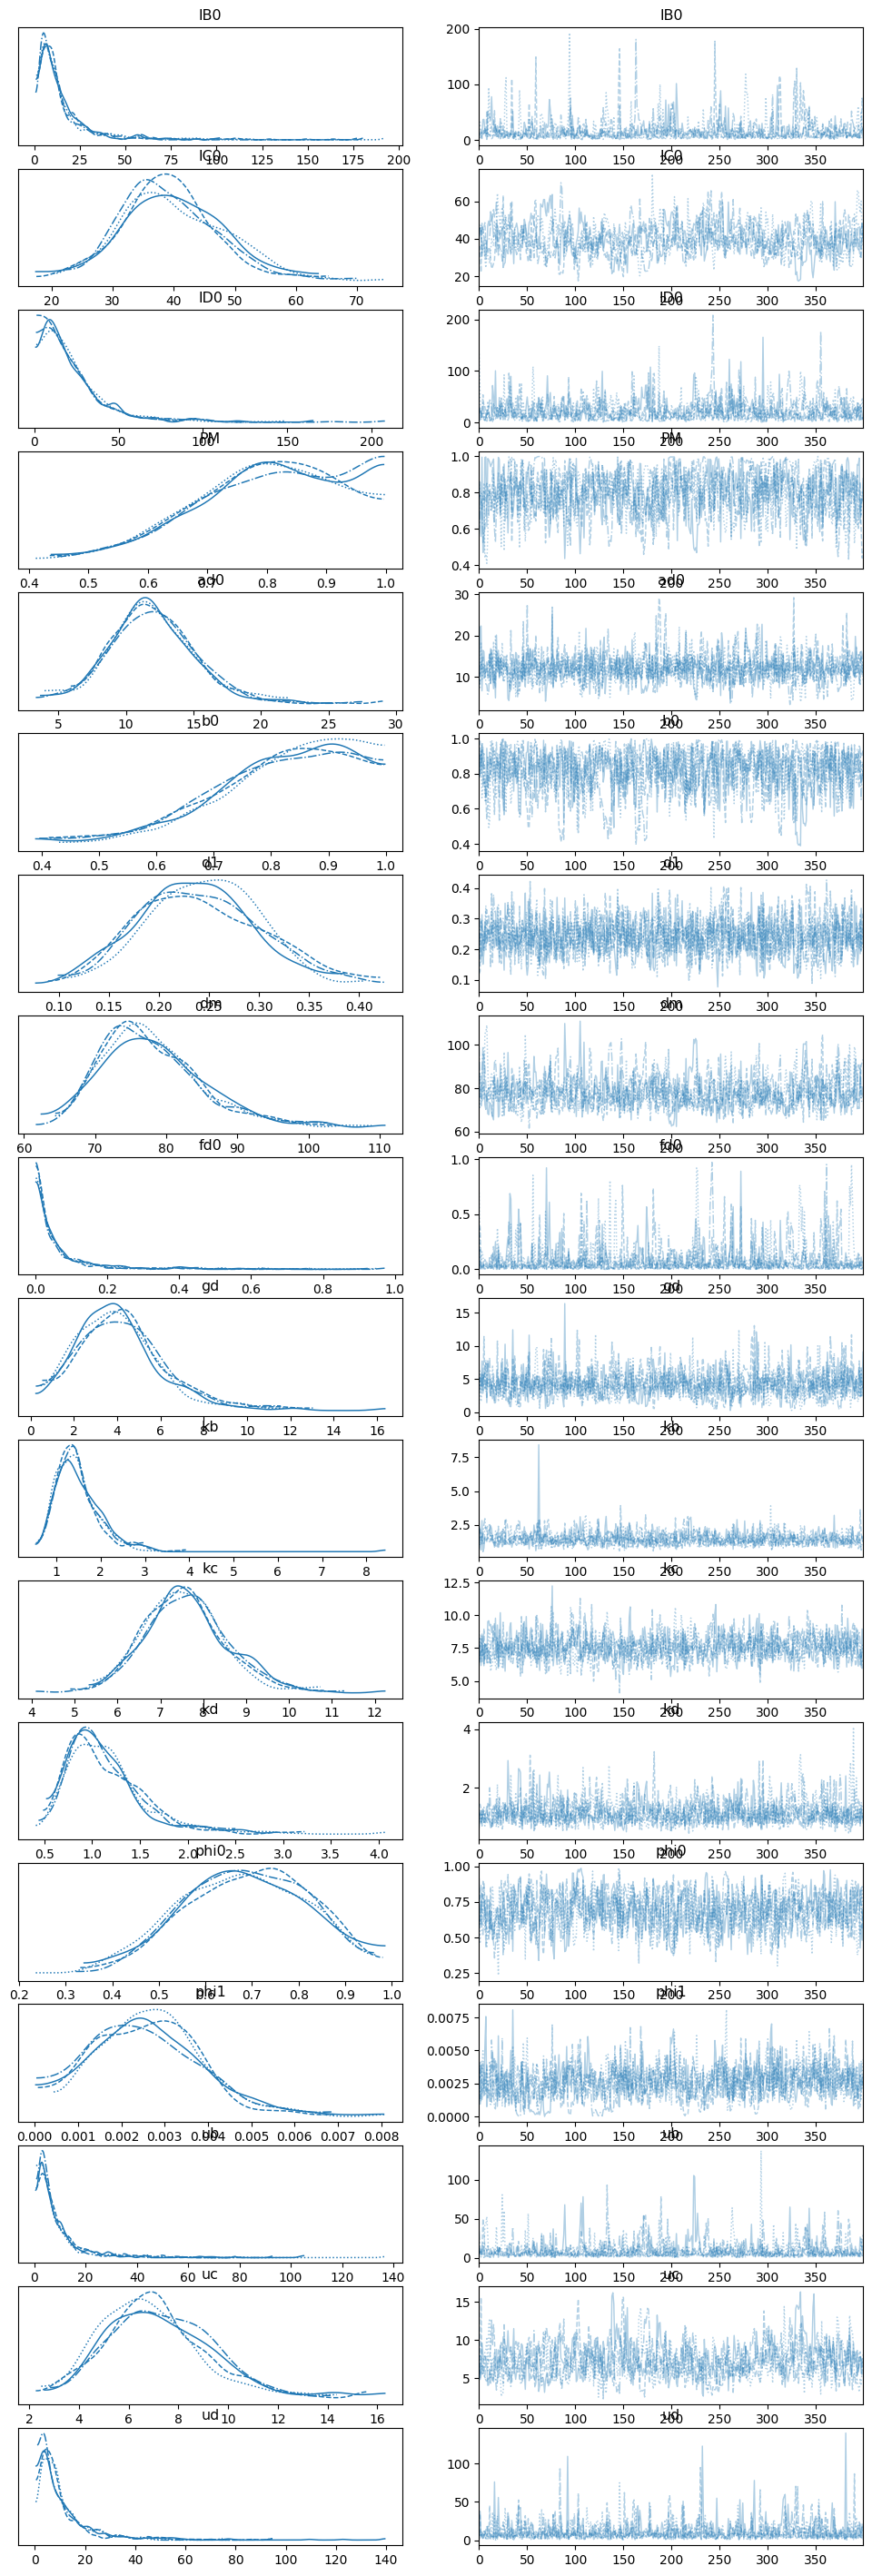

In [5]:
az.plot_trace(idata, var_names=params)
plt.show()

In [8]:
import numpy as np
import pandas as pd
import arviz as az
from msinf.data import encode_canonical_sites, site_to_study_from_df

run = "outputs/2026-10-14/15-54-43"
d = np.load(f"{run}/numpyro_jamie_samples.npz")

# Posterior draws, (chain, draw, ...)
post = {k: d[k] for k in d.files
        if not k.startswith("warmup__") and k != "__grouped_by_chain__"}
# Warmup draws, renamed so warmup__IC0 becomes IC0
warm = {k.removeprefix("warmup__"): d[k] for k in d.files if k.startswith("warmup__")}

# Site and study names for the vector axes (see the earlier note on ordering)
df, site_labels = encode_canonical_sites(pd.read_csv("artifacts/inputs/study_data_2014.csv"))
_, _, study_levels = site_to_study_from_df(df)

idata = az.from_dict(
    posterior=post,
    warmup_posterior=warm,
    save_warmup=True,
    coords={"site": site_labels, "study": study_levels},
    dims={"log_eir": ["site"], "ft_study": ["study"]},
)
idata


Inference data with groups:
	> posterior

Warmup iterations saved (warmup_*).

In [9]:
az.summary(idata)                                   # every parameter
# az.summary(idata, var_names=["IC0", "kc", "sigma_c"])
# az.summary(idata, var_names=["log_eir"])            # one row per site
# az.summary(idata, var_names=["~log_eir", "~ft_study"])  # ~ excludes, here leaving the scalars only


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
IB0,15.550,18.289,0.831,42.583,0.677,1.307,602.0,843.0,1.00
IC0,39.598,8.275,23.178,54.530,0.471,0.276,305.0,568.0,1.01
ID0,21.899,20.232,0.627,55.507,0.792,1.133,570.0,945.0,1.01
PM,0.799,0.123,0.590,0.999,0.006,0.003,403.0,468.0,1.01
ad0,12.079,3.376,5.793,18.630,0.098,0.117,1128.0,743.0,1.00
...,...,...,...,...,...,...,...,...,...
sigma_c,1.068,0.194,0.730,1.411,0.009,0.003,524.0,1165.0,1.01
sigma_p,0.936,0.190,0.607,1.297,0.006,0.005,906.0,962.0,1.00
ub,9.103,11.272,0.574,27.992,0.435,0.910,960.0,836.0,1.00
uc,7.202,2.183,3.409,11.263,0.128,0.084,293.0,416.0,1.01


In [10]:
from msinf.compare import load_draws_npz
import arviz as az

draws = load_draws_npz("/home/athapar/code/msinf/outputs/2026-10-14/15-54-43/numpyro_jamie_samples.npz", drop_warmup=False)


<Axes: title={'center': 'IC0'}, xlabel='Total number of draws', ylabel='ESS'>

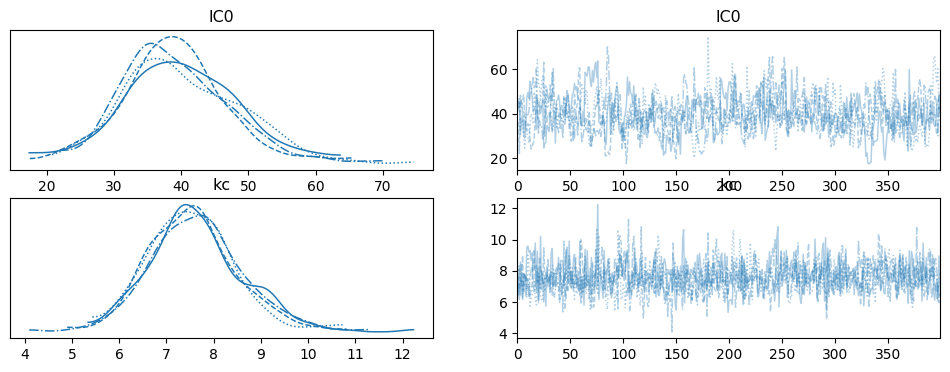

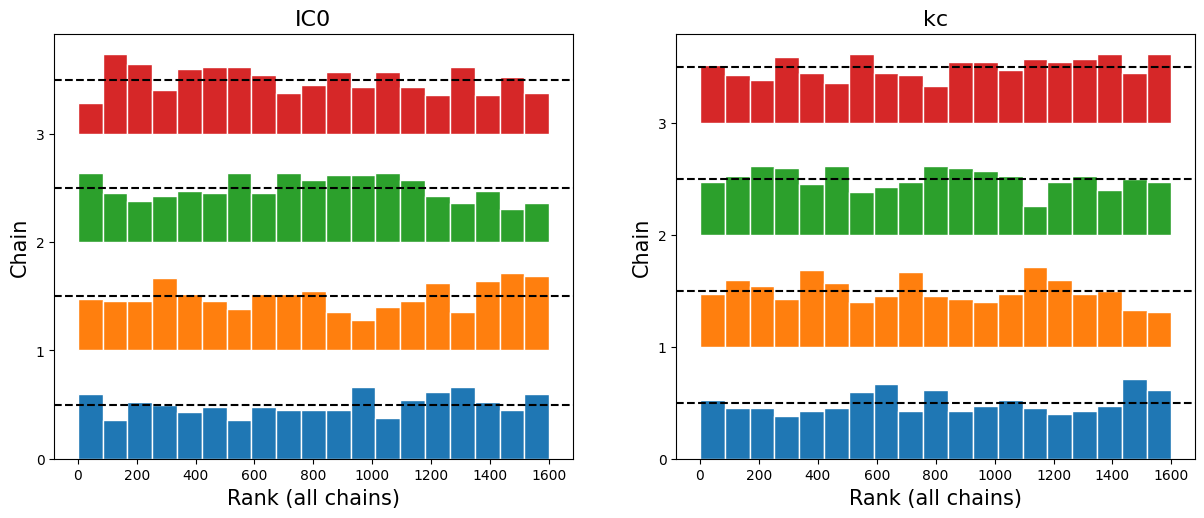

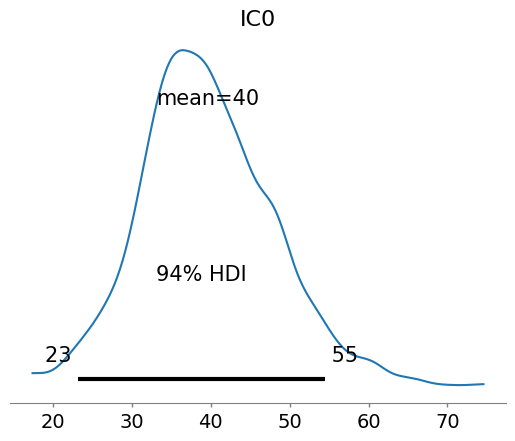

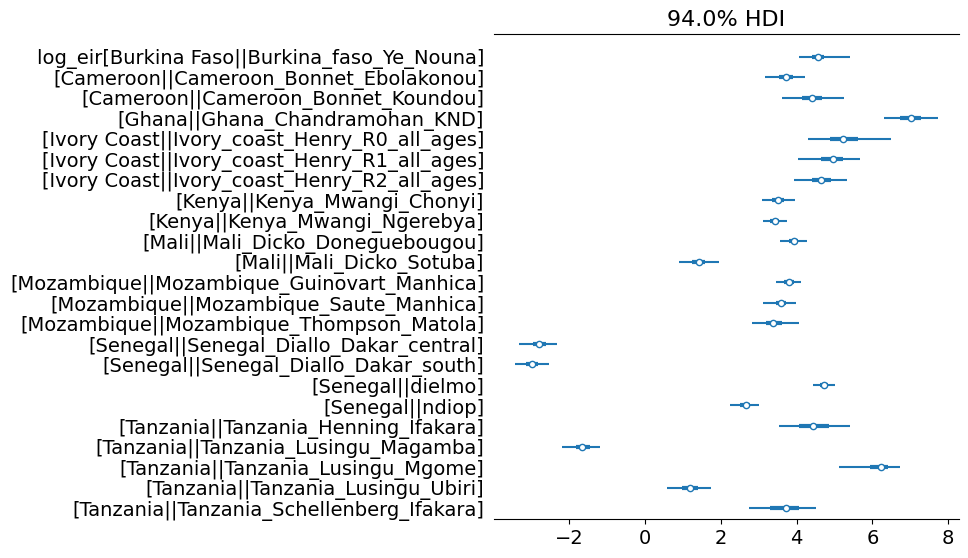

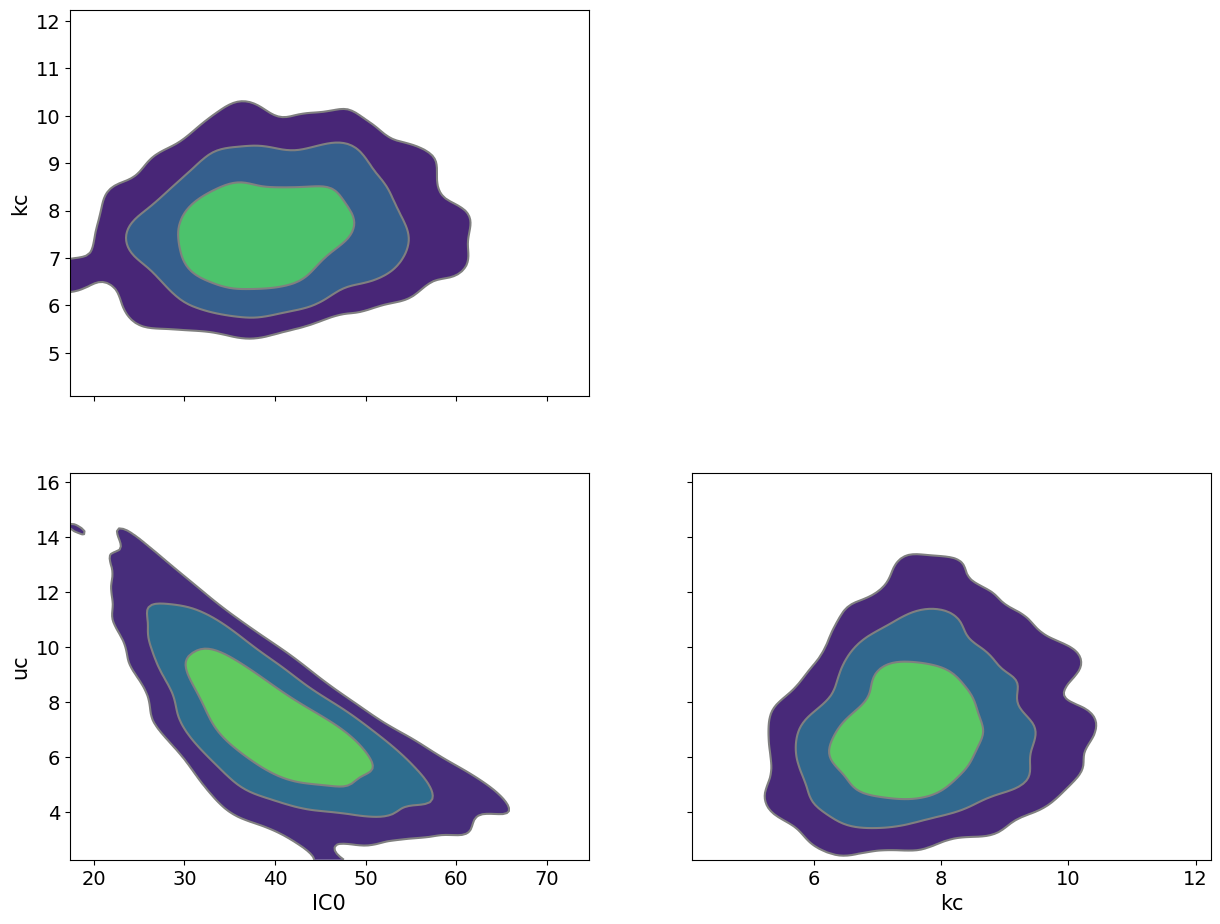

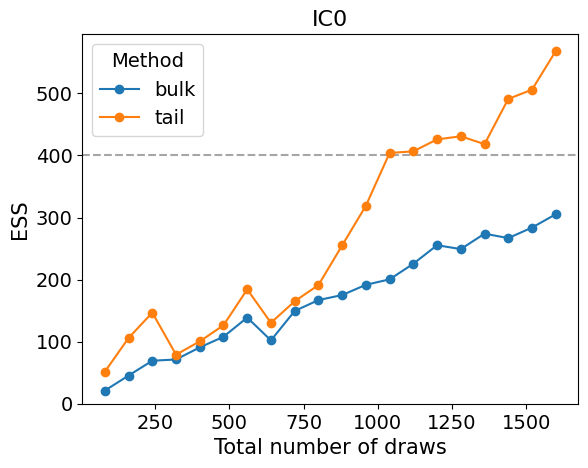

In [11]:
az.plot_trace(idata, var_names=["IC0", "kc"])          # density and trace per chain
az.plot_rank(idata, var_names=["IC0", "kc"])           # rank plots, the better mixing check
az.plot_posterior(idata, var_names=["IC0"])            # posterior with HDI
az.plot_forest(idata, var_names=["log_eir"], combined=True)  # all 23 sites at once
az.plot_pair(idata, var_names=["IC0", "kc", "uc"], kind="kde")  # correlations between parameters
az.plot_ess(idata, var_names=["IC0"], kind="evolution")


In [ ]:
from pathlib import Path
from IPython.display import Image, display
from msinf.plotting import plot_all_study_trajectories

pngs = plot_all_study_trajectories(
    "outputs/2026-10-14/15-54-43/numpyro_jamie_samples.npz",
    "artifacts/inputs/study_data_2014.csv",
    outdir=Path("artifacts/figures/trajectories"),
    n_draws=100,
    effects="conditional",
    max_age=20,
    ncols=4,
)
for outcome, path in pngs.items():
    print(f"{outcome}: {path}")
    display(Image(filename=str(path)))


In [44]:
import pandas as pd

nuts_draws = pd.read_csv("artifacts/draws/nuts_posterior_draws.csv")
nuts_summary = (
    nuts_draws.groupby("parameter", sort=False)["value"]
    .agg(mean="mean", std="std", num_draws="count")
    .reset_index()
    .rename(columns={"parameter": "param"})
)

nuts_summary


,param,mean,std,num_draws
0,ib0,36.791788,63.555240,400
1,ic0,26.943247,7.464922,400
2,id0,81.679395,46.266766,400
3,pcm,0.751332,0.129495,400
4,ad,4693.179502,1577.768519,400
...,...,...,...,...
56,sigma_c,0.950721,0.174878,400
57,sigma_p,0.806103,0.159333,400
58,ub,20.010352,25.584138,400
59,uc,11.061641,3.989923,400


incidence: artifacts/figures/trajectories-jitter/all_studies_incidence.png


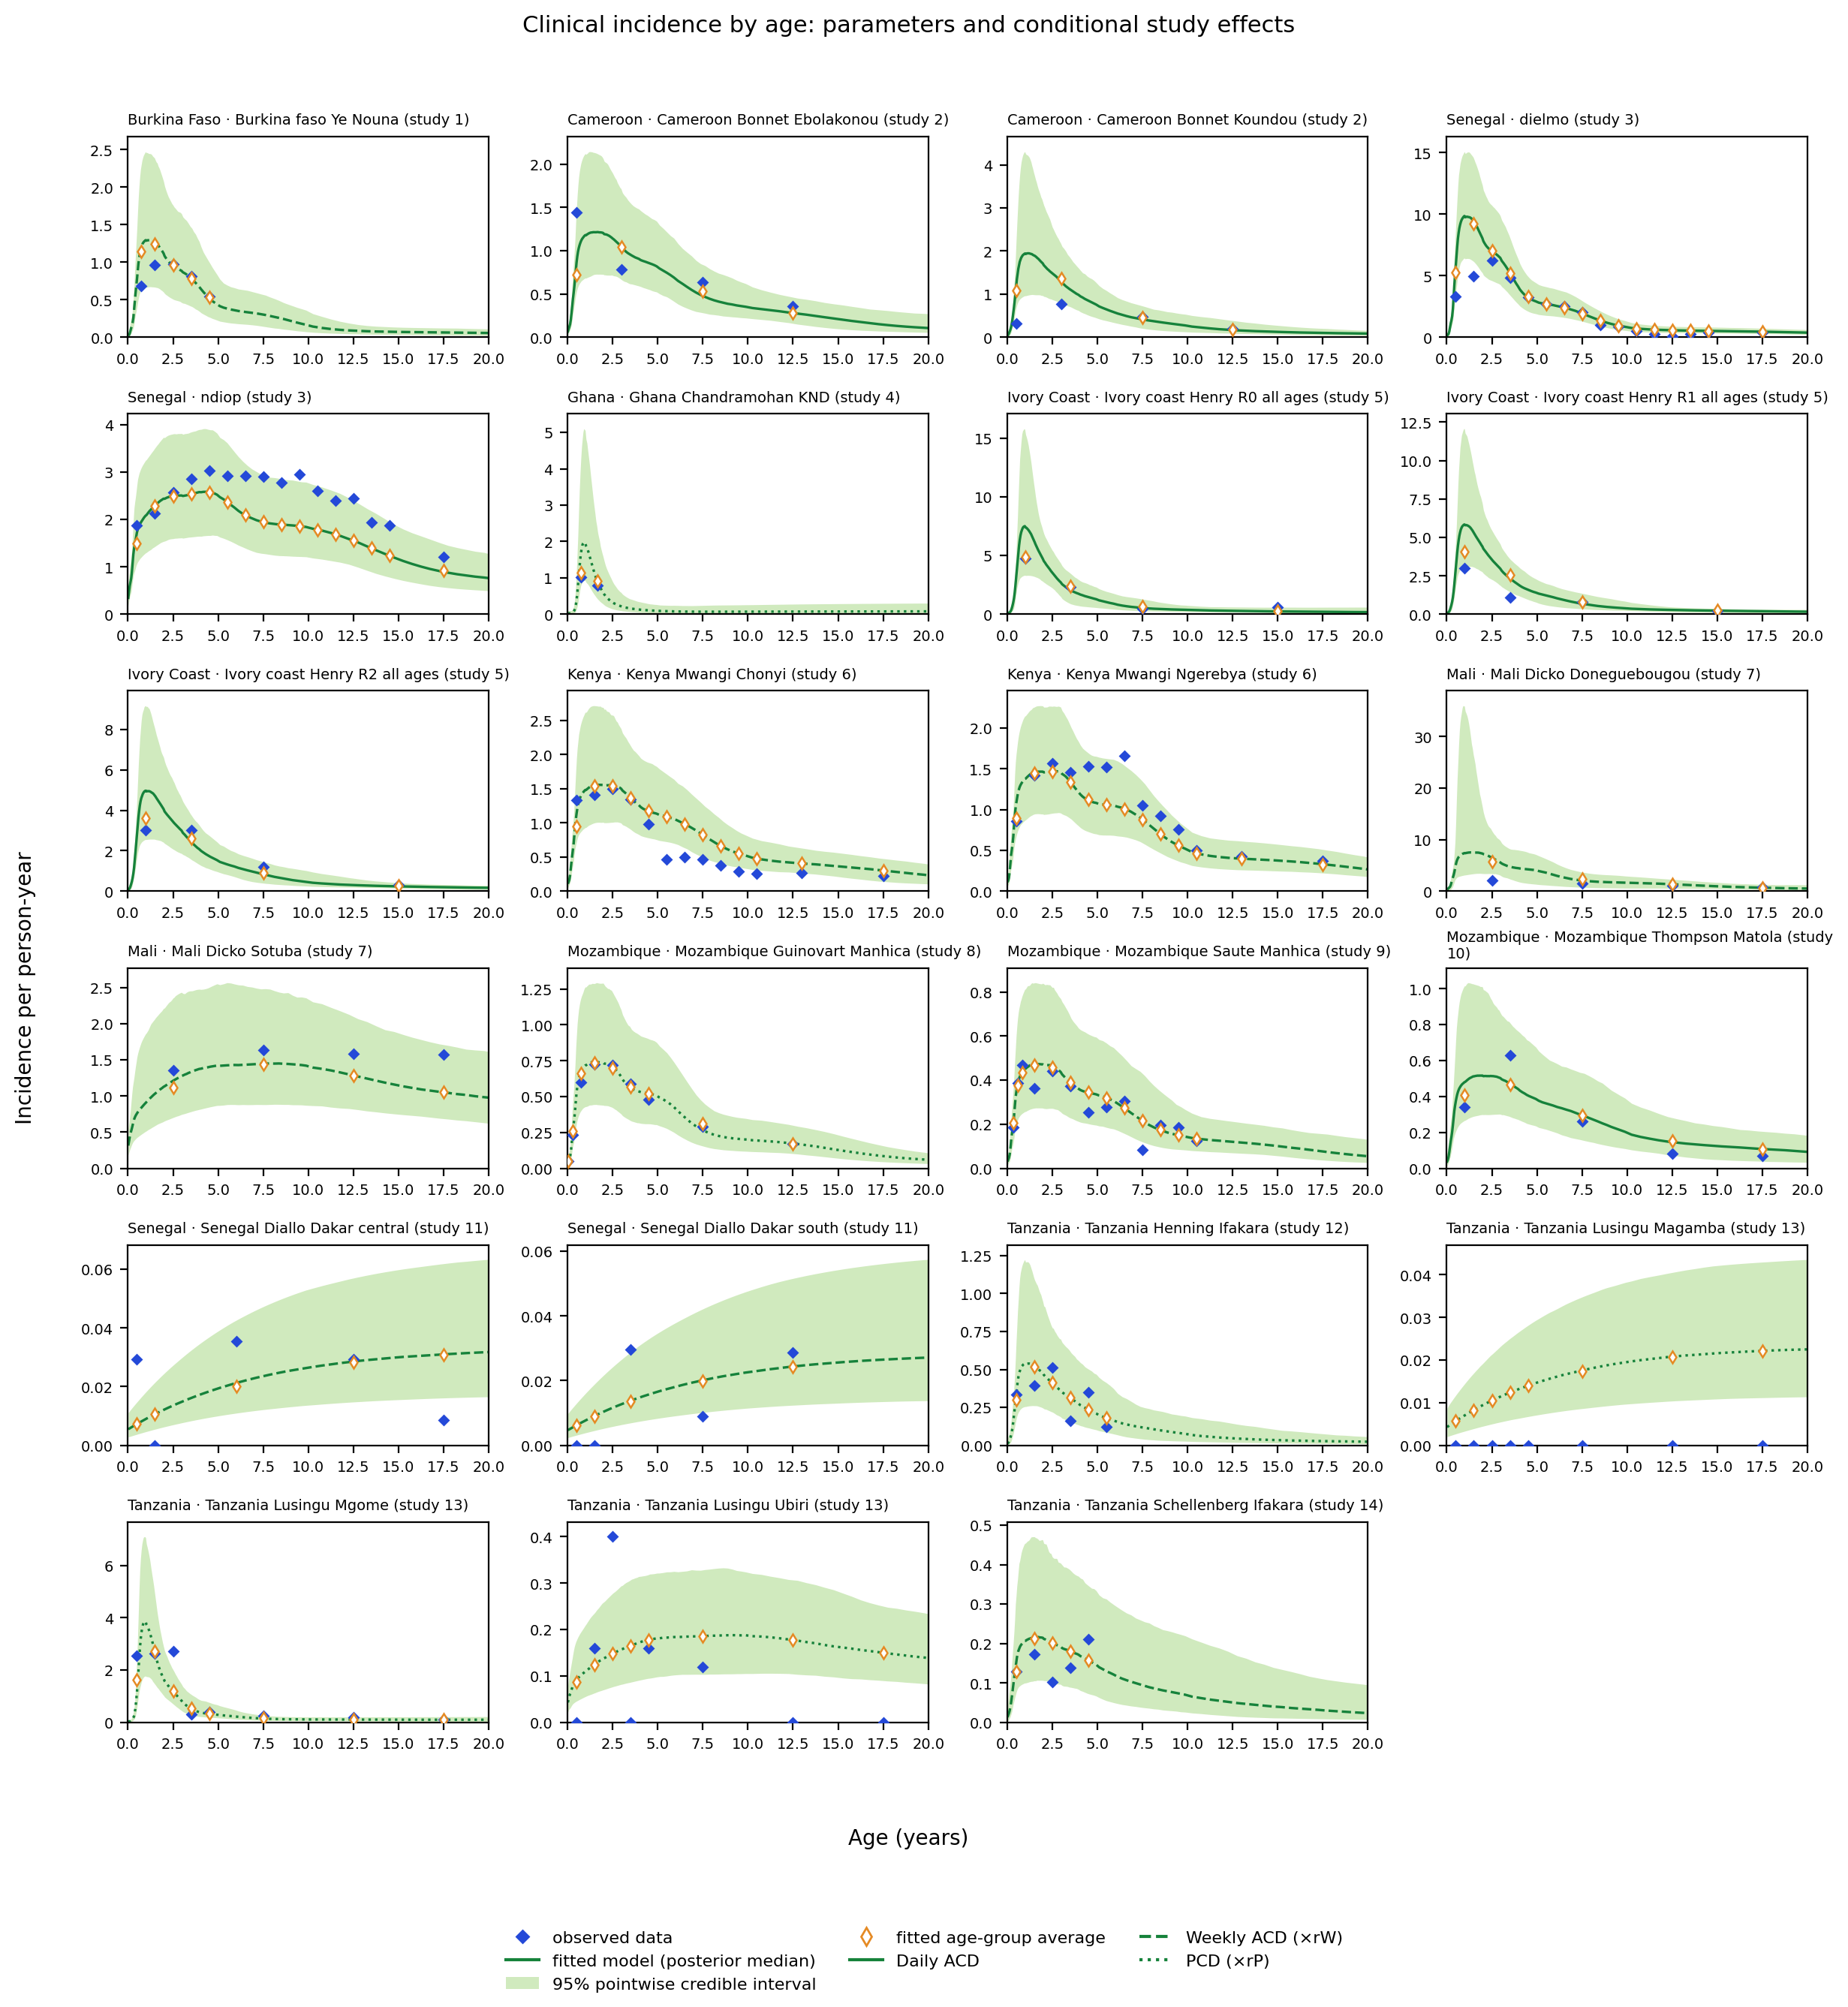

prevalence: artifacts/figures/trajectories-jitter/all_studies_prevalence.png


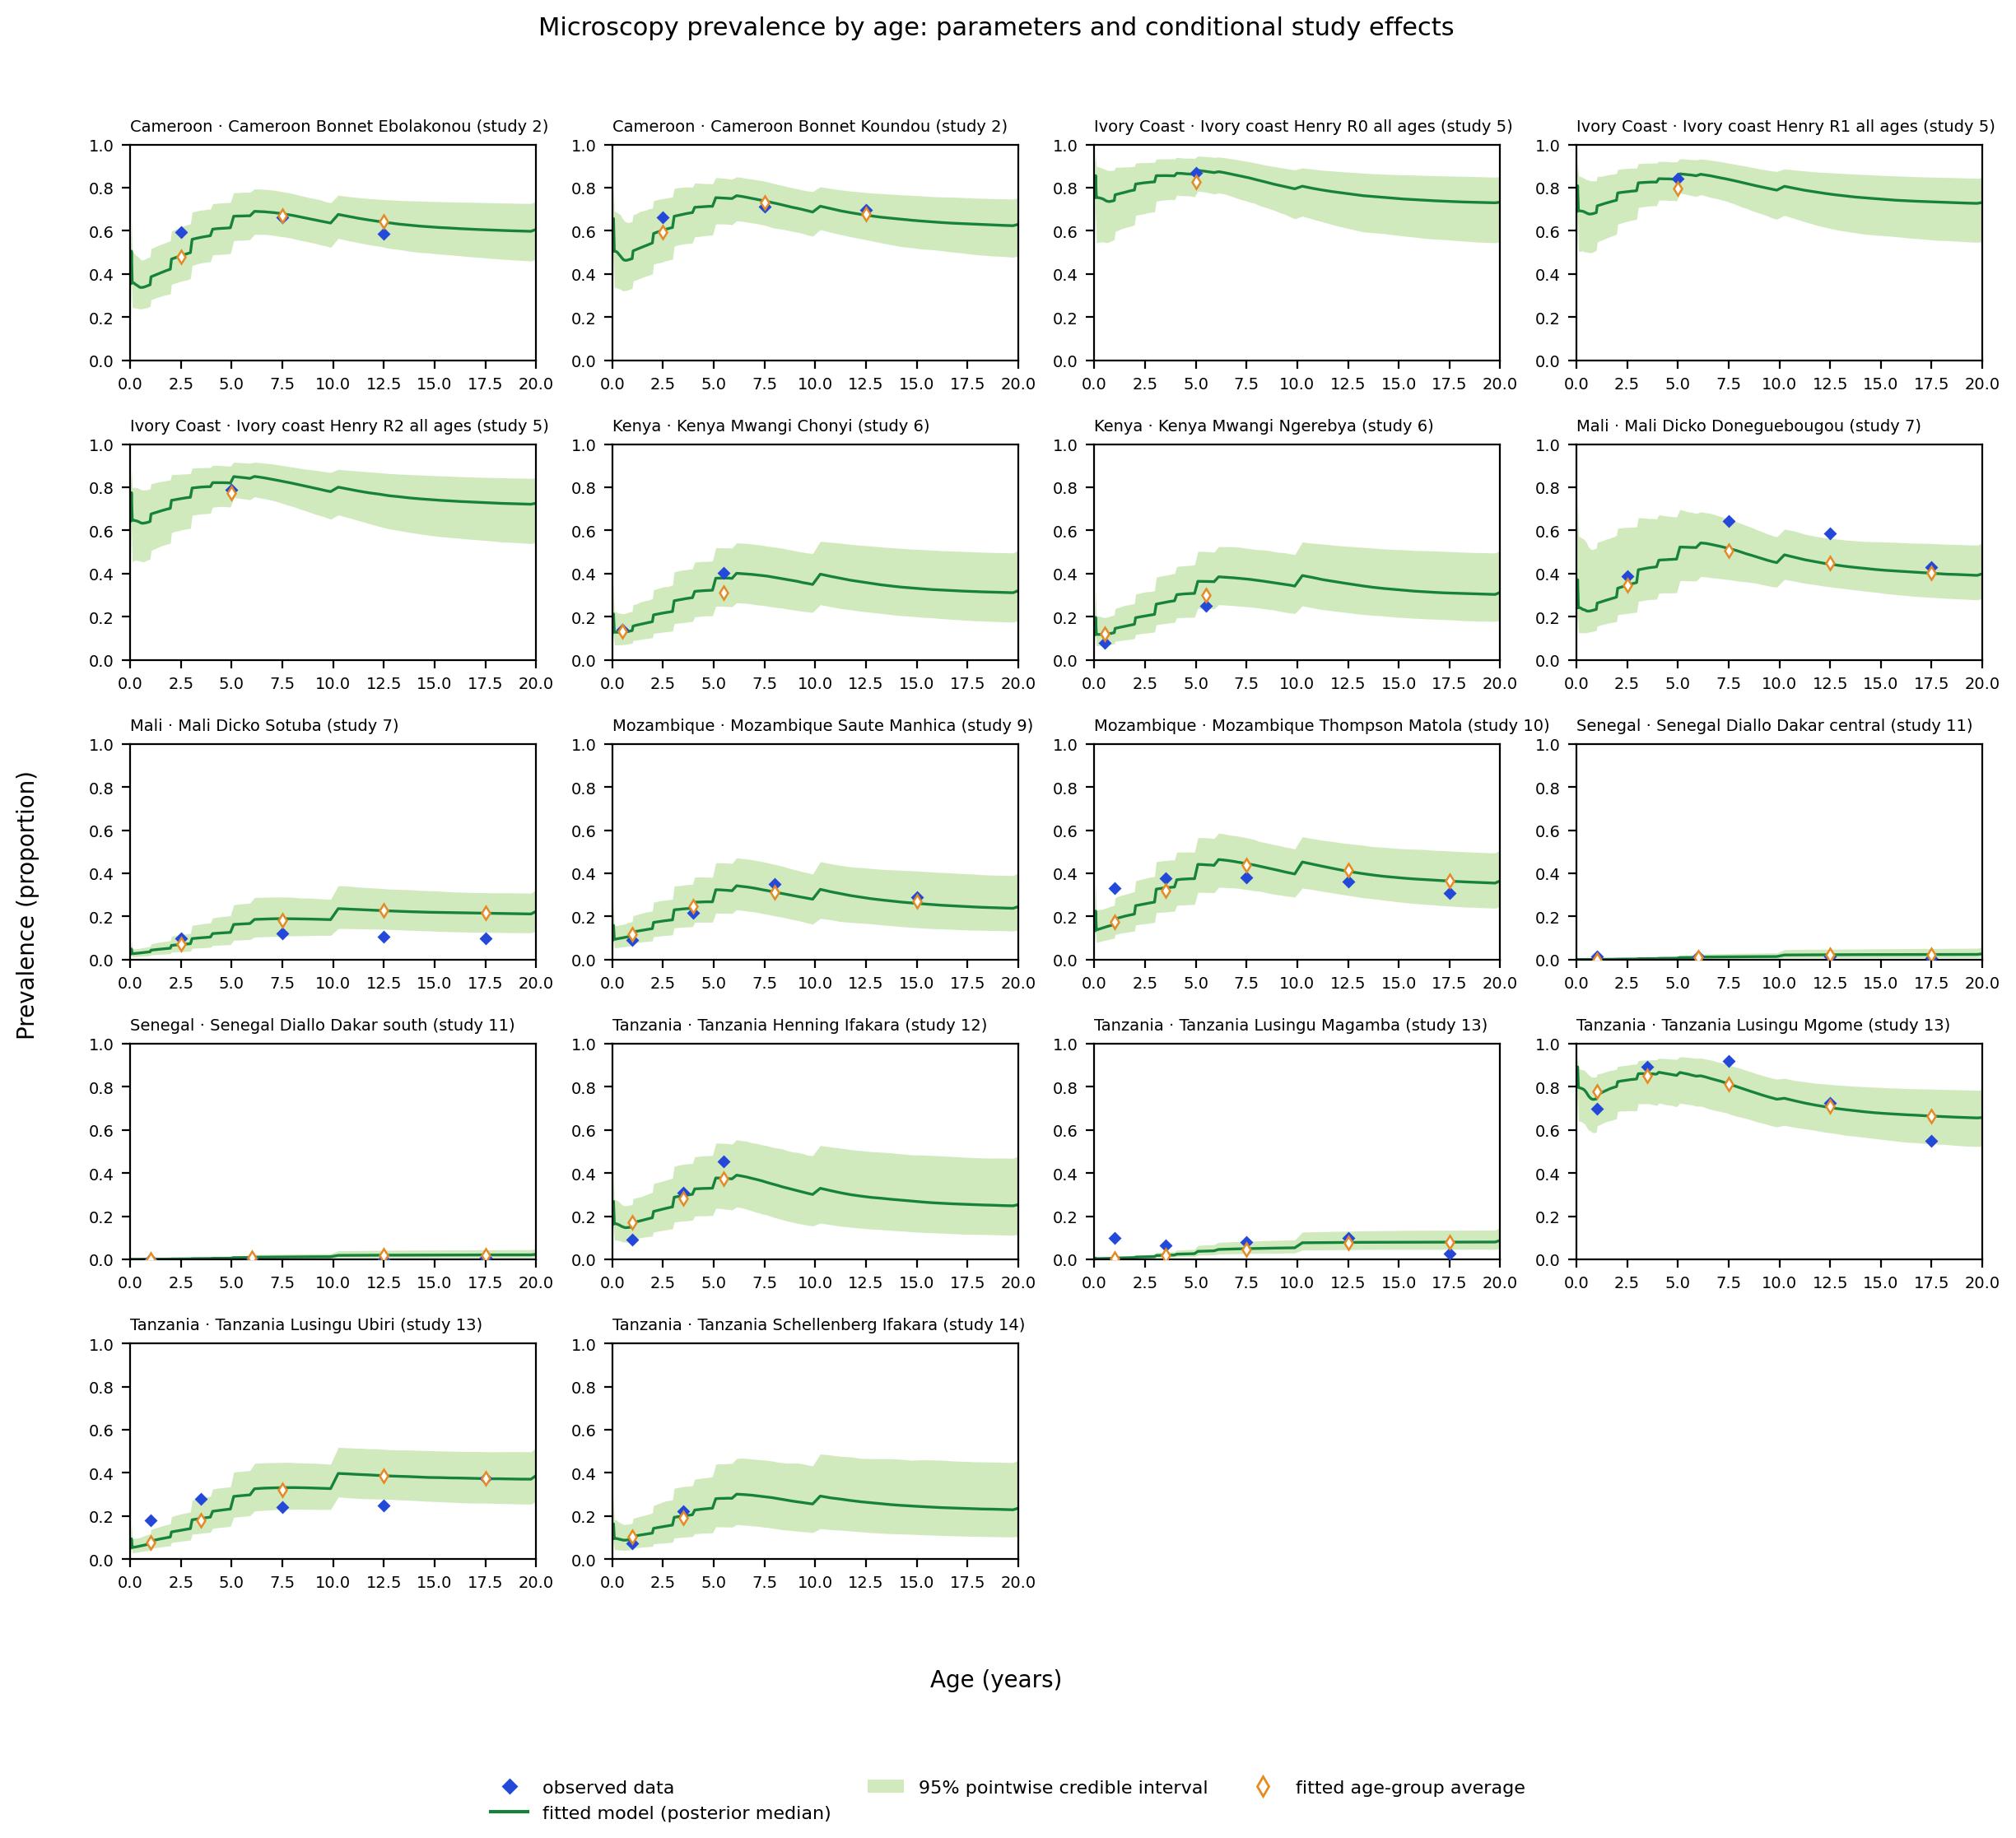

In [1]:
from pathlib import Path
from IPython.display import Image, display
from msinf.plotting import plot_all_study_trajectories

pngs = plot_all_study_trajectories(
    "/home/athapar/code/msinf/outputs/2026-10-19/11-02-22/numpyro_jamie_samples.npz",
    "artifacts/inputs/study_data_2014.csv",
    outdir=Path("artifacts/figures/trajectories-jitter"),
    n_draws=100,
    effects="conditional",
    max_age=20,
    ncols=4,
)
for outcome, path in pngs.items():
    print(f"{outcome}: {path}")
    display(Image(filename=str(path)))

In [ ]:

# plotting with bad site removed
pngs = plot_all_study_trajectories(
    "/home/athapar/code/msinf/outputs/2026-10-19/13-47-42/numpyro_jamie_samples.npz",
    "artifacts/inputs-no-Mali_Dicko_Doneguebougou/study_data_2014.csv",
    outdir=Path("artifacts/figures/trajectories-jitter-badsite-removed"),
    n_draws=100,
    effects="conditional",
    max_age=20,
    ncols=4,
)


IndexError: index 22 is out of bounds for axis 1 with size 22